# Task 6: MLOps and deployment simulation

This notebook reviews the Task 6 outputs. It is **read-only**: it does not train or register models and does not change aliases or the saved outputs. Refresh them first from the repository root, in this order (after Tasks 1-4):

```powershell
python Part-3/model_versions.py   # 6.1 / 6.2: versions v2 and v3, comparison, champion alias
python Part-3/monitoring.py       # 6.4 / 6.5: drift checks, status file and HTML dashboard
python Part-3/serve_api.py        # 6.3: FastAPI service (leave running; open /docs)
```

The notebook needs `Part-3/mlflow.db`, `Part-3/mlartifacts/` and the Task 6 files in `Part-3/outputs/`. `mlartifacts/` is git-ignored, so on a fresh checkout re-run Tasks 1-4 and the commands above first.

Scope reminder: the data is one corridor, hourly. The model predicts **same-hour traffic volume** (not accidents, so the proxy-label caveat does not apply here). Monitoring is a replay of the held-out test period (2017-10-26 to 2018-09-30), not live traffic.

**How to use this notebook:** run the cells in order. Sections 6.1 and 6.2 read saved version and experiment results; section 6.3 calls the actual API in-process; sections 6.4 and 6.5 explain the saved replay and demonstrate the monitoring rules. The editable examples do not change the registry or saved reports.

The notebook expects its working directory to be `Part-3/notebooks/` (as when opened directly or executed with the README command). Install the Part 3 dependencies described in the README, including `fastapi`, `uvicorn`, `httpx`, Jupyter and `nbconvert`. A running API server is not needed for the in-process examples.


In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import pandas as pd
from IPython.display import HTML, Image, display

PART_DIR = Path.cwd().resolve().parent
OUT = PART_DIR / "outputs"
sys.path.insert(0, str(PART_DIR))
TRACKING_URI = f"sqlite:///{(PART_DIR / 'mlflow.db').as_posix()}"
mlflow.set_tracking_uri(TRACKING_URI)
client = mlflow.MlflowClient()
MODEL = "traffic-volume-regressor"
pd.options.display.max_columns = 30
pd.options.display.max_colwidth = 90


def need(name):
    path = OUT / name
    if not path.exists():
        raise FileNotFoundError(f"Run the Task 6 scripts first; missing {path}")
    return path


print(f"Part 3 directory: {PART_DIR}")
print(f"Tracking URI: {TRACKING_URI}")

Part 3 directory: C:\Users\prati\Desktop\NUS AI Course\Capstone Project\Submission\Part-3
Tracking URI: sqlite:///C:/Users/prati/Desktop/NUS AI Course/Capstone Project/Submission/Part-3/mlflow.db


## 6.1 Model versioning

`traffic-volume-regressor` has three versions in the MLflow Model Registry. All use the same 28 Task 1 features, the same chronological 80/20 split and the same random state, so they are directly comparable:

| Version | Model | How it was made |
|---|---|---|
| v1 | Random Forest (300 trees, `min_samples_leaf=5`) | Task 1 model, registered by Task 4 |
| v2 | Gradient Boosting (300 trees, depth 5, learning rate 0.1, subsample 0.8) | Task 6; settings chosen for this simulation, not tuned |
| v3 | Random Forest, `min_samples_leaf` and `max_features` tuned | Task 6; 4 x 4 grid, 3-fold time-ordered cross-validation on the **training period only** |

Each version was reloaded from the registry and scored on the test period. The `champion` alias moves only to a version that beats v1 on test MAE **and** reproduces the metric logged by its training run (the Task 4 promotion gate, tolerance 0.05 vehicles/h); otherwise v1 stays champion.

### Read the version comparison

MAE is the average absolute prediction error in vehicles/hour (lower is better). RMSE also penalizes larger errors more heavily; R² compares explained variation with a mean-prediction baseline (higher is better). The gate checks whether the reloaded artifact reproduces its logged MAE; passing it is not proof of production readiness.

The CSV and chart are saved results, whereas the next registry cell reads the *current* alias. If they disagree, rerun the versioning script and monitoring before interpreting the dashboard.

,version,label,model,key_params,train_MAE,MAE,RMSE,R2,logged_MAE,abs_difference,gate_passed,source_experiment,mae_vs_v1_pct,alias
0,1,random-forest-task1,RandomForestRegressor,"{""max_depth"": null, ""max_features"": 1.0, ""min_samples_leaf"": 5, ""n_estimators"": 300}",183.9932,238.8709,400.0866,0.9588,238.8709,0.0,True,task1-supervised-models,0.0000,NaN
1,2,gradient-boosting,GradientBoostingRegressor,"{""learning_rate"": 0.1, ""max_depth"": 5, ""max_features"": null, ""min_samples_leaf"": 1, ""n...",211.5437,239.7923,399.7202,0.9588,239.7923,0.0,True,task6-model-versions,0.3858,NaN
2,3,tuned-random-forest,RandomForestRegressor,"{""max_depth"": null, ""max_features"": 0.5, ""min_samples_leaf"": 5, ""n_estimators"": 300}",193.7214,236.7518,399.2476,0.9589,236.7518,0.0,True,task6-model-versions,-0.8871,champion


Promotion decision: v3 beats v1 (MAE 236.75 vs 238.87) and passed the gate


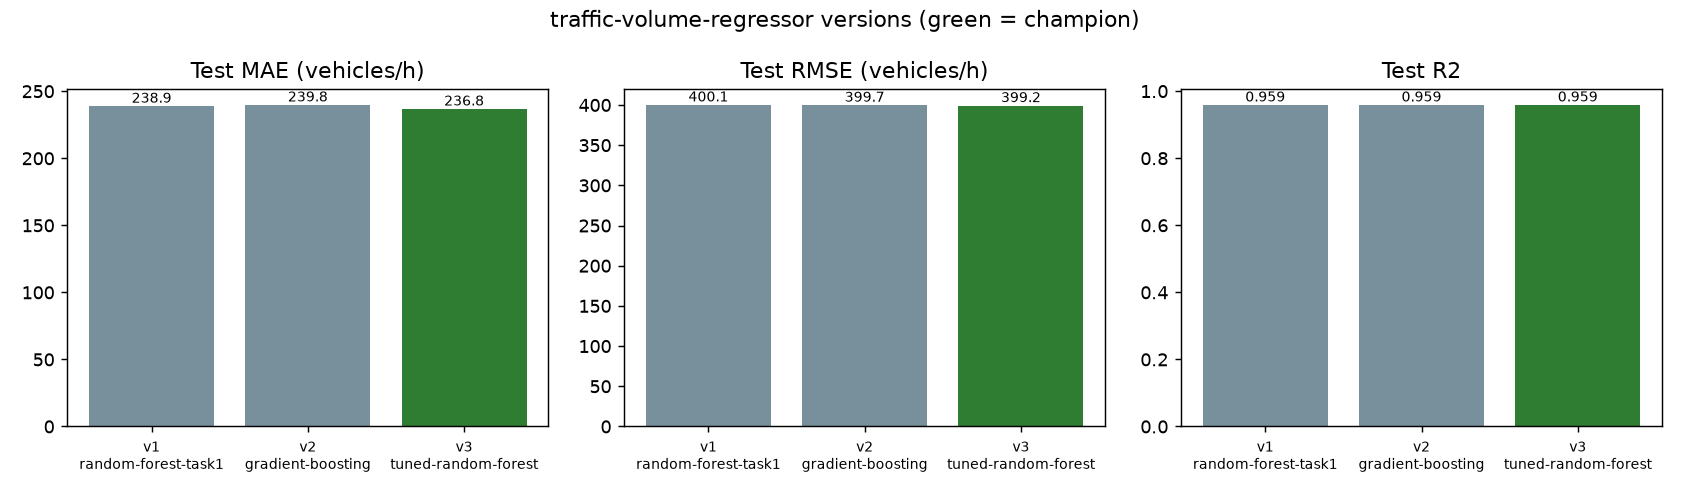

In [2]:
versions = pd.read_csv(need("model_versions.csv"))
display(versions.drop(columns=["source_run_id", "promotion_note"]))
print("Promotion decision:", versions["promotion_note"].iloc[0])
display(Image(filename=str(need("model_versions.png"))))

In [3]:
print(f"{MODEL}: aliases={client.get_registered_model(MODEL).aliases}")
for v in sorted(client.search_model_versions(f"name='{MODEL}'"), key=lambda v: int(v.version)):
    tags = {k: t for k, t in v.tags.items() if k.startswith("test_") or k in ("version_label", "gate_passed")}
    print(f"  v{v.version}: source run {v.tags.get('source_run_id')}; {tags}")

traffic-volume-regressor: aliases={'champion': 3}
  v1: source run d6f25cbab87248bab73283482a2c0d12; {'test_MAE': '238.8709', 'test_RMSE': '400.0866', 'test_R2': '0.9588', 'gate_passed': 'True'}
  v2: source run 1b956bc9a07c4de3a6ef809f6c1ea825; {'version_label': 'gradient-boosting', 'test_MAE': '239.7923', 'test_RMSE': '399.7202', 'test_R2': '0.9588', 'gate_passed': 'True'}
  v3: source run e6dc3ff7c87343fda8d725b8e87faeb7; {'version_label': 'tuned-random-forest', 'test_MAE': '236.7518', 'test_RMSE': '399.2476', 'test_R2': '0.9589', 'gate_passed': 'True'}


**Reading the comparison.** The three versions are very close: v3 beats v1 by about 2 vehicles/h of MAE (under 1%), and v2 is slightly worse than v1 on MAE but marginally better on RMSE. The tuned grid selected the same `min_samples_leaf` as v1 and differs only in `max_features` (0.5 instead of all features). With a single time split, no repeated runs and the test set used both for scoring and for the champion choice, this gap is **not** evidence that v3 is meaningfully better; the promotion follows the agreed rule rather than a significance test.

## 6.2 Experiment tracking with MLflow

Two new experiments hold the Task 6 runs (alongside the Task 1-3 experiments): `task6-model-versions` (one run per trained version plus a comparison run) and `task6-monitoring` (one run per monitoring replay). MLflow stores the parameters, metrics, fitted model and output files for each run.

In [4]:
rows = []
for experiment in client.search_experiments():
    if not experiment.name.startswith("task6-"):
        continue
    for run in client.search_runs([experiment.experiment_id], max_results=1000):
        rows.append({
            "experiment": experiment.name,
            "run_name": run.info.run_name,
            "start_time": pd.to_datetime(run.info.start_time, unit="ms", utc=True).strftime("%Y-%m-%d %H:%M"),
            "run_id": run.info.run_id,
            **{k: round(v, 3) for k, v in run.data.metrics.items()},
        })
task6_runs = pd.DataFrame(rows).sort_values(["experiment", "start_time"]).reset_index(drop=True)
print(f"{len(task6_runs)} Task 6 runs")
display(task6_runs.drop(columns="run_id"))

6 Task 6 runs


,experiment,run_name,start_time,reference_MAE,windows_evaluated,windows_alert,latest_MAE,latest_mae_ratio,latest_max_psi_whole_period,latest_max_psi_same_month,overall_alert,versions_compared,gates_passed,champion_version,best_test_MAE,MAE,RMSE,R2,train_MAE,fit_seconds
0,task6-model-versions,Random Forest (tuned) (tuned-random-forest),2026-11-25 02:58,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,236.752,399.248,0.959,193.721,47.176
1,task6-model-versions,Gradient Boosting (gradient-boosting),2026-11-25 02:58,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,239.792,399.720,0.959,211.544,11.315
2,task6-model-versions,version comparison,2026-11-25 02:59,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0,3.0,3.0,236.752,NaN,NaN,NaN,NaN,NaN
3,task6-model-versions,version comparison,2026-11-25 03:05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0,3.0,3.0,236.752,NaN,NaN,NaN,NaN,NaN
4,task6-monitoring,monitoring replay (traffic-volume-regressor v3),2026-11-25 03:03,236.752,12.0,12.0,180.878,0.764,2.187,0.39,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,task6-monitoring,monitoring replay (traffic-volume-regressor v3),2026-11-25 03:06,236.752,12.0,12.0,180.878,0.764,2.187,0.39,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
train_runs = [
    run
    for experiment in client.search_experiments()
    if experiment.name == "task6-model-versions"
    for run in client.search_runs([experiment.experiment_id], filter_string="tags.version_label != ''")
]
for run in sorted(train_runs, key=lambda r: r.info.start_time):
    params = {k: v for k, v in run.data.params.items() if k.startswith("model__") and k not in ("model__verbose", "model__warm_start")}
    print(run.info.run_name, "| metrics:", {k: round(v, 3) for k, v in run.data.metrics.items()})
    print("   key parameters:", {k: params[k] for k in params if k.split("__")[1] in
          ("n_estimators", "learning_rate", "max_depth", "subsample", "min_samples_leaf", "max_features")})
display(pd.read_csv(need("model_versions_rf_tuning.csv")).head(8))

Gradient Boosting (gradient-boosting) | metrics: {'MAE': 239.792, 'RMSE': 399.72, 'R2': 0.959, 'train_MAE': 211.544, 'fit_seconds': 11.315}
   key parameters: {'model__learning_rate': '0.1', 'model__max_depth': '5', 'model__max_features': 'None', 'model__min_samples_leaf': '1', 'model__n_estimators': '300', 'model__subsample': '0.8'}
Random Forest (tuned) (tuned-random-forest) | metrics: {'MAE': 236.752, 'RMSE': 399.248, 'R2': 0.959, 'train_MAE': 193.721, 'fit_seconds': 47.176}
   key parameters: {'model__max_depth': 'None', 'model__max_features': '0.5', 'model__min_samples_leaf': '5', 'model__n_estimators': '300'}


,min_samples_leaf,max_features,cv_MAE,rank_test_score
0,5,0.50,267.9209,1
1,5,0.33,267.9933,2
2,10,0.50,268.0354,3
3,10,0.75,268.9616,4
4,10,0.33,269.7040,5
5,5,0.75,269.9903,6
6,2,0.33,270.4706,7
7,20,0.50,270.6756,8


The tuning table is the cross-validated MAE on the training period for each grid point (best first). The scores are close across the grid (a few vehicles/h), so the choice of `max_features` matters little.

## 6.3 Deployment mock-up (FastAPI)

`Part-3/serve_api.py` serves `models:/traffic-volume-regressor@champion` with FastAPI. Run it from the repository root and open the interactive docs:

```powershell
python Part-3/serve_api.py        # http://127.0.0.1:8000/docs
```

Endpoints: `GET /health`, `GET /model`, `POST /predict` (calendar and weather of the hour in, predicted vehicles/hour and the Part 2 traffic category out) and `GET /monitor/status` (the latest saved PASS/ALERT status). The cell below calls the same application in-process with FastAPI's `TestClient`, so it needs no running server.

### Try several input scenarios

`TestClient` loads the registered champion and calls the same FastAPI application without opening a network port. Each example supplies the weather for the **hour being predicted**, so these are same-hour estimates, not forecasts made without knowing that weather. The model version in each response identifies the artifact actually used.

In [6]:
from fastapi.testclient import TestClient

import serve_api

with TestClient(serve_api.create_app(serve_api.Settings(mlflow_uri=TRACKING_URI, status_file=OUT / "monitoring_status.json"))) as api:
    print("GET /health ->", api.get("/health").json())
    print("GET /model  ->", api.get("/model").json())
    scenarios = {
        "Thursday 17:00, cloudy, 22.5 C": {"timestamp": "2018-06-14T17:00:00", "temp_c": 22.5, "rain_1h": 0, "snow_1h": 0, "clouds_all": 40, "weather_main": "Clouds"},
        "Saturday 03:00, clear, 15 C": {"timestamp": "2018-06-16T03:00:00", "temp_c": 15, "rain_1h": 0, "snow_1h": 0, "clouds_all": 10, "weather_main": "Clear"},
        "Tuesday 08:00, snow, -5 C": {"timestamp": "2018-01-16T08:00:00", "temp_c": -5, "rain_1h": 0, "snow_1h": 0.3, "clouds_all": 90, "weather_main": "Snow"},
        "25 Dec 12:00, clear, 0 C (holiday)": {"timestamp": "2017-12-25T12:00:00", "temp_c": 0, "rain_1h": 0, "snow_1h": 0, "clouds_all": 5, "weather_main": "Clear", "is_holiday": True},
    }
    results = []
    for label, body in scenarios.items():
        reply = api.post("/predict", json=body).json()
        results.append({"scenario": label, "predicted vehicles/h": reply["predicted_traffic_volume"],
                        "category": reply["traffic_category"], "congested": reply["is_congested"],
                        "model version": reply["model_version"]})
    display(pd.DataFrame(results))
    bad = api.post("/predict", json={**scenarios["Saturday 03:00, clear, 15 C"], "weather_main": "Hail"})
    print("Unknown weather ->", bad.status_code, bad.json()["detail"])
    print("GET /monitor/status ->", api.get("/monitor/status").json()["label"])

GET /health -> {'status': 'ok', 'model_loaded': True}
GET /model  -> {'name': 'traffic-volume-regressor', 'version': '3', 'alias': 'champion', 'n_features': 28, 'weather_groups': ['Clear', 'Clouds', 'Drizzle', 'Fog', 'Haze', 'Mist', 'Rain', 'Smoke', 'Snow', 'Squall', 'Thunderstorm'], 'unit': 'vehicles/hour'}


,scenario,predicted vehicles/h,category,congested,model version
0,"Thursday 17:00, cloudy, 22.5 C",6098.5,High,True,3
1,"Saturday 03:00, clear, 15 C",447.7,Low,False,3
2,"Tuesday 08:00, snow, -5 C",4727.1,Medium,False,3
3,"25 Dec 12:00, clear, 0 C (holiday)",3922.6,Low,False,3


Unknown weather -> 422 Unknown weather_main 'Hail'. Use one of: Clear, Clouds, Drizzle, Fog, Haze, Mist, Rain, Smoke, Snow, Squall, Thunderstorm.
GET /monitor/status -> ALERT / Requires investigation


### Try your own request

Edit the values below and rerun this cell. `timestamp` uses the dataset's local time; `temp_c` is Celsius, rain and snow are hourly amounts in mm, and `clouds_all` is a percentage. `is_holiday` is a caller-provided whole-day flag. Use a weather group returned by `/model`. This example shows the entire JSON response, including the model version and threshold explanation.

In [7]:
# Change these values to explore another hypothetical hour.
my_request = {
    "timestamp": "2018-06-14T17:00:00",
    "temp_c": 22.5,
    "rain_1h": 0.0,
    "snow_1h": 0.0,
    "clouds_all": 40,
    "weather_main": "Clouds",
    "is_holiday": False,
}

with TestClient(serve_api.create_app(serve_api.Settings(
    mlflow_uri=TRACKING_URI, status_file=OUT / "monitoring_status.json"
))) as api:
    response = api.post("/predict", json=my_request)
    response.raise_for_status()
    print("Request:")
    print(json.dumps(my_request, indent=2))
    print("Response:")
    print(json.dumps(response.json(), indent=2))

Request:


{
  "timestamp": "2018-06-14T17:00:00",
  "temp_c": 22.5,
  "rain_1h": 0.0,
  "snow_1h": 0.0,
  "clouds_all": 40,
  "weather_main": "Clouds",
  "is_holiday": false
}
Response:
{
  "predicted_traffic_volume": 6098.5,
  "unit": "vehicles/hour",
  "traffic_category": "High",
  "is_congested": true,
  "category_note": "Part 2 traffic_category: Low < 4,500; Medium 4,500-5,500; High > 5,500 vehicles/hour (the project's fixed thresholds, not the Part 3 quartile categories).",
  "model_name": "traffic-volume-regressor",
  "model_version": "3",
  "model_alias": "champion"
}


### Input validation examples

The service returns HTTP 422 for an unknown weather group or out-of-range cloud cover instead of producing a prediction. These deliberately invalid requests are examples only; they do not alter model or monitoring data.

In [8]:
invalid_requests = {
    "unknown weather": {**my_request, "weather_main": "Hail"},
    "cloud cover above 100%": {**my_request, "clouds_all": 150},
}
with TestClient(serve_api.create_app(serve_api.Settings(
    mlflow_uri=TRACKING_URI, status_file=OUT / "monitoring_status.json"
))) as api:
    for label, payload in invalid_requests.items():
        response = api.post("/predict", json=payload)
        print(f"{label}: HTTP {response.status_code}")
        print(json.dumps(response.json(), indent=2))

unknown weather: HTTP 422
{
  "detail": "Unknown weather_main 'Hail'. Use one of: Clear, Clouds, Drizzle, Fog, Haze, Mist, Rain, Smoke, Snow, Squall, Thunderstorm."
}


cloud cover above 100%: HTTP 422
{
  "detail": [
    {
      "type": "less_than_equal",
      "loc": [
        "body",
        "clouds_all"
      ],
      "msg": "Input should be less than or equal to 100",
      "input": 150,
      "ctx": {
        "le": 100.0
      }
    }
  ]
}


These are model outputs for hypothetical hours, not forecasts of a specific day. The category uses the project's fixed Part 2 thresholds (Low < 4,500; Medium 4,500-5,500; High > 5,500 vehicles/h), not the Part 3 quartile categories. The service has no authentication, TLS or scaling, and loads a pickled model, so only serve models from a trusted store.

## 6.4 Monitoring: feature and prediction-error drift

`Part-3/monitoring.py` replays the test period in consecutive calendar months against the training period and checks:

- **Feature distribution drift:** Population Stability Index (PSI) for `temp_c`, `rain_1h`, `snow_1h`, `clouds_all`, `hour` and the `weather_main` mix, against (a) the whole training period and (b) the same calendar month in the training period. The worse of the two drives the status.
- **Prediction error drift:** the month's MAE against the model's full test-period MAE.

Thresholds (heuristic conventions, **not** derived from this data; logged at every run): PSI >= 0.2 is an ALERT (0.1-0.2 a warning only) and a month MAE above 1.25 x the reference MAE is an ALERT. No month is excluded for having few hours, so short months give noisier values.

### How the checks work

**MAE example:** for observations of 100 and 200 vehicles/hour and predictions of 110 and 180, the absolute errors are 10 and 20, so MAE is `(10 + 20) / 2 = 15`. The monitor compares each month's MAE with `1.25 ×` the full test-period MAE; equality is PASS, and only a value above the limit is ALERT. This reference includes the evaluated month and would not be available in advance in a real replay.

**PSI:** the monitor divides a numeric training reference into up to 10 quantile-derived bins and compares the proportion of current and reference observations in each bin. It sums `(current share − reference share) × ln(current share / reference share)` across bins, flooring tiny shares to avoid division by zero. The weather-mix PSI uses category shares instead. Large PSI indicates a distribution shift, not necessarily a model failure or its cause.

For each feature, both the whole-training and same-calendar-month references are checked: **either** can trigger a feature ALERT. A PSI from 0.1 up to (but excluding) 0.2 is a warning; 0.2 or above is an ALERT. These limits are illustrative heuristics, not validated operating requirements.

In [9]:
report = pd.read_csv(need("monitoring_report.csv"))
display(report[["window", "n_hours", "MAE", "mae_ratio", "error_status", "max_psi_whole_period",
                "max_psi_same_month", "feature_alerts", "feature_warnings", "status"]])

drift = pd.read_csv(need("monitoring_feature_drift.csv"))
for column, title in (("psi_whole_period", "PSI vs the whole training period"),
                      ("psi_same_month", "PSI vs the same calendar month in the training period")):
    print(title)
    display(drift.pivot(index="window", columns="feature", values=column).round(2)
            .style.map(lambda v: "background-color:#ef9a9a" if v >= 0.2 else ("background-color:#fff59d" if v >= 0.1 else "background-color:#c8e6c9")))

,window,n_hours,MAE,mae_ratio,error_status,max_psi_whole_period,max_psi_same_month,feature_alerts,feature_warnings,status
0,2017-10,126,239.2388,1.0105,PASS,6.2332,6.5026,"temp_c, rain_1h, clouds_all, weather_main",NaN,ALERT
1,2017-11,716,293.2197,1.2385,PASS,3.0738,1.2431,"temp_c, rain_1h, clouds_all, weather_main",NaN,ALERT
2,2017-12,740,347.1372,1.4662,ALERT,3.7624,0.3324,"temp_c, rain_1h, clouds_all, weather_main",NaN,ALERT
3,2018-01,742,311.7017,1.3166,ALERT,4.3207,1.3086,"temp_c, rain_1h, clouds_all, weather_main",NaN,ALERT
4,2018-02,672,235.2554,0.9937,PASS,4.5070,0.3281,"temp_c, rain_1h, clouds_all, weather_main",NaN,ALERT
5,2018-03,733,216.6298,0.9150,PASS,4.2621,0.5363,"temp_c, rain_1h, clouds_all, weather_main",NaN,ALERT
6,2018-04,720,308.6062,1.3035,ALERT,0.9484,0.7015,"temp_c, rain_1h, weather_main",clouds_all,ALERT
7,2018-05,743,180.2402,0.7613,PASS,2.6835,0.5376,"temp_c, rain_1h, weather_main",clouds_all,ALERT
8,2018-06,719,162.8497,0.6878,PASS,3.9236,1.8191,"temp_c, rain_1h, clouds_all, weather_main",NaN,ALERT
9,2018-07,744,195.1938,0.8245,PASS,4.2089,0.3607,"temp_c, rain_1h, clouds_all, weather_main",NaN,ALERT


PSI vs the whole training period


feature,clouds_all,hour,rain_1h,snow_1h,temp_c,weather_main
window,,,,,,
2017-10,1.130000,0.000000,0.320000,0.000000,6.230000,0.930000
2017-11,0.220000,0.000000,0.320000,0.000000,3.070000,0.410000
2017-12,0.280000,0.000000,0.320000,0.000000,3.760000,0.700000
2018-01,0.230000,0.000000,0.320000,0.000000,4.320000,1.100000
2018-02,0.260000,0.000000,0.320000,0.000000,4.510000,1.140000
2018-03,0.220000,0.000000,0.320000,0.000000,4.260000,0.210000
2018-04,0.180000,0.000000,0.320000,0.000000,0.950000,0.410000
2018-05,0.200000,0.000000,0.320000,0.000000,2.680000,0.360000
2018-06,0.230000,0.000000,0.320000,0.000000,3.920000,0.470000


PSI vs the same calendar month in the training period


feature,clouds_all,hour,rain_1h,snow_1h,temp_c,weather_main
window,,,,,,
2017-10,2.410000,0.000000,0.160000,0.000000,6.500000,1.620000
2017-11,1.240000,0.000000,0.010000,0.000000,0.360000,0.230000
2017-12,0.300000,0.000000,0.150000,0.040000,0.330000,0.220000
2018-01,1.310000,0.000000,0.120000,0.010000,0.040000,0.320000
2018-02,0.190000,0.000000,0.020000,0.000000,0.130000,0.330000
2018-03,0.020000,0.000000,0.230000,0.000000,0.540000,0.200000
2018-04,0.170000,0.000000,0.700000,0.000000,0.580000,0.570000
2018-05,0.170000,0.000000,0.470000,0.000000,0.540000,0.110000
2018-06,1.820000,0.000000,0.790000,0.000000,0.260000,0.110000


### A worked month from the actual replay

This cell explains the latest saved month using the same thresholds and helper functions as `monitoring.py`. A model can have acceptable prediction error and still alert because an input distribution changed.

In [10]:
import monitoring

latest = report.iloc[-1]
feature_details = drift[drift["window"] == latest["window"]].copy()
print(f"Month: {latest['window']} ({int(latest['n_hours'])} observed hours)")
print(f"MAE: {latest['MAE']:.2f} vehicles/hour; "
      f"limit: {monitoring.ERROR_RATIO_ALERT:.2f} × {latest['reference_MAE']:.2f} = "
      f"{monitoring.ERROR_RATIO_ALERT * latest['reference_MAE']:.2f}")
print("Error check:", monitoring.error_status(latest["MAE"], latest["reference_MAE"]))
print("Overall recorded status:", latest["status"])
display(feature_details[["feature", "psi_whole_period", "status_whole_period",
                         "psi_same_month", "status_same_month", "status"]])

Month: 2018-09 (720 observed hours)
MAE: 180.88 vehicles/hour; limit: 1.25 × 236.75 = 295.94
Error check: PASS
Overall recorded status: ALERT


,feature,psi_whole_period,status_whole_period,psi_same_month,status_same_month,status
66,temp_c,2.1866,ALERT,0.1038,WARNING,ALERT
67,rain_1h,0.5087,ALERT,0.3897,ALERT,ALERT
68,snow_1h,0.0019,PASS,0.0000,PASS,PASS
69,clouds_all,0.2069,ALERT,0.3344,ALERT,ALERT
70,hour,0.0002,PASS,0.0012,PASS,PASS
71,weather_main,0.5820,ALERT,0.2365,ALERT,ALERT


### What do PASS and ALERT look like?

The following small **synthetic examples** call the same PSI and error-status helpers used by the monitor. They illustrate the rules only: they are not added to the historical replay, do not change its status or thresholds, and do not simulate production traffic.

In [11]:
reference_mix = ["Clear"] * 50 + ["Rain"] * 50
examples = {
    "same mix": ["Clear"] * 50 + ["Rain"] * 50,
    "changed mix": ["Clear"] * 90 + ["Rain"] * 10,
}
example_rows = []
for label, current_mix in examples.items():
    psi = monitoring.categorical_psi(reference_mix, current_mix, ["Clear", "Rain"])
    example_rows.append({
        "example": label, "clear share": current_mix.count("Clear") / len(current_mix),
        "PSI": round(psi, 4), "feature check": monitoring.psi_status(psi),
    })
display(pd.DataFrame(example_rows))

reference_mae = 200.0  # Illustrative vehicles/hour, not the saved model's test MAE.
error_rows = []
for monthly_mae in (200.0, 250.0, 300.0):
    error_rows.append({
        "monthly MAE": monthly_mae, "reference MAE": reference_mae,
        "limit": monitoring.ERROR_RATIO_ALERT * reference_mae,
        "error check": monitoring.error_status(monthly_mae, reference_mae),
    })
display(pd.DataFrame(error_rows))

,example,clear share,PSI,feature check
0,same mix,0.5,0.0000,PASS
1,changed mix,0.9,0.8789,ALERT


,monthly MAE,reference MAE,limit,error check
0,200.0,200.0,250.0,PASS
1,250.0,200.0,250.0,PASS
2,300.0,200.0,250.0,ALERT


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
colours = ["#c62828" if s == "ALERT" else "#2e7d32" for s in report["error_status"]]
axes[0].bar(report["window"], report["MAE"], color=colours)
axes[0].axhline(report["reference_MAE"].iloc[0], color="black", ls="--", label="reference MAE (full test period)")
axes[0].axhline(1.25 * report["reference_MAE"].iloc[0], color="#c62828", ls=":", label="alert: 1.25 x reference")
axes[0].set_title("Prediction error by month")
axes[0].set_ylabel("MAE (vehicles/h)")
axes[0].legend(fontsize=8)
axes[1].plot(report["window"], report["max_psi_whole_period"], marker="o", label="max PSI vs whole training period")
axes[1].plot(report["window"], report["max_psi_same_month"], marker="s", label="max PSI vs same training month")
axes[1].axhline(0.1, color="#f9a825", ls=":", label="warning 0.1")
axes[1].axhline(0.2, color="#c62828", ls=":", label="alert 0.2")
axes[1].set_yscale("symlog", linthresh=0.1)
axes[1].set_title("Worst feature PSI by month")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()

C:\Users\prati\AppData\Local\Temp\ipykernel_6180\3926901499.py:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [13]:
shares = pd.read_csv(need("monitoring_weather_shares.csv"))
last = shares[shares["window"] == shares["window"].max()].set_index("weather_main")
print(f"weather_main share in {shares['window'].max()} vs training (rows are weather groups)")
display((last[["share_training_period", "share_same_month_training", "share_window"]] * 100).round(1))

weather_main share in 2018-09 vs training (rows are weather groups)


,share_training_period,share_same_month_training,share_window
weather_main,,,
Clear,32.4,43.0,29.9
Clouds,38.8,27.2,31.9
Drizzle,1.2,0.9,1.2
Fog,0.5,0.7,0.1
Haze,1.9,2.1,0.6
Mist,7.4,7.6,2.9
Rain,12.0,16.8,32.4
Smoke,0.0,0.0,0.0
Snow,4.9,0.0,0.0


**What the replay shows.**

- *Prediction error* is within the 1.25x limit in 9 of 12 months; the three months above it are December 2017, January 2018 and April 2018. This is an observation about this one replay, not a diagnosis of the cause.
- *Feature drift* triggers in every month. The whole-period reference mostly flags **seasonality** (temperature differs by season; it alerts for `temp_c` in all 12 months). The same-calendar-month reference reduces this seasonal mismatch, but still alerts in every month, through `weather_main` (9 months), `clouds_all` (8), `rain_1h` (7) and `temp_c` (7); `hour` and `snow_1h` never reach a threshold. The recorded test-period feature distributions differ from the training references, but this alone cannot distinguish weather changes from recording or data-quality issues. The cause is not established by this check.
- `rain_1h` is recorded as exactly 0 for all of 2017 in the source data (and non-zero in about 6% of hours in 2018), so rain in later months looks like a shift. This is a property of the data (possibly a recording gap), not evidence about the weather itself.
- The first month (26-31 Oct 2017) has only 126 hours, and every other month is a single sample of about 700 hours, so a PSI near the threshold is noisy; the Oct 2017 PSI values are the largest.

## 6.5 Alerting: PASS / ALERT

The status is written to `outputs/monitoring_status.json` (also served by `GET /monitor/status`), logged as a WARNING when it is ALERT, and shown on the colour-coded dashboard `outputs/monitoring_dashboard.html`. The script's exit code is 0 for PASS, 2 for ALERT (as in Task 4, 2 means a check failed) and 1 for an error. The overall status is the status of the **latest month** evaluated; the dashboard lists every month.

In [14]:
status = json.loads(need("monitoring_status.json").read_text(encoding="utf-8"))
colour = "#2e7d32" if status["overall_status"] == "PASS" else "#c62828"
display(HTML(
    f'<div style="background:{colour};color:white;padding:12px 18px;border-radius:8px;font-size:20px;">'
    f'<b>{status["label"]}</b><br><span style="font-size:13px">latest month {status["latest_window"]} | '
    f'{status["windows_alert"]} of {status["windows_evaluated"]} months ALERT | '
    f'model {status["model"]["name"]} v{status["model"]["version"]} (@{status["model"]["alias"]})</span></div>'
))
print("Reasons for the latest month:")
for reason in status["reasons"]:
    print(" -", reason)
print("Thresholds:", status["thresholds"])
print(f"Open the full dashboard in a browser: {OUT / 'monitoring_dashboard.html'}")

Reasons for the latest month:
 - Feature drift in temp_c: PSI 2.19 vs the whole training period, 0.10 vs the same training month (alert at 0.2; breached vs whole training period).
 - Feature drift in rain_1h: PSI 0.51 vs the whole training period, 0.39 vs the same training month (alert at 0.2; breached vs whole training period and same training month).
 - Feature drift in clouds_all: PSI 0.21 vs the whole training period, 0.33 vs the same training month (alert at 0.2; breached vs whole training period and same training month).
 - Feature drift in weather_main: PSI 0.58 vs the whole training period, 0.24 vs the same training month (alert at 0.2; breached vs whole training period and same training month).
Thresholds: {'psi_warning': 0.1, 'psi_alert': 0.2, 'error_ratio_alert': 1.25, 'psi_bins': 10, 'note': 'heuristic conventions, not derived from this data'}
Open the full dashboard in a browser: C:\Users\prati\Desktop\NUS AI Course\Capstone Project\Submission\Part-3\outputs\monitoring_das

## Limitations

- **Simulation, not production.** Monitoring replays historical test data; there is no live feed, automatic retraining, paging or approval workflow. The API is a local mock-up (no authentication, TLS, scaling or request logging to a store).
- **Thresholds are conventions.** The PSI and error-ratio limits are common rules of thumb chosen for this simulation and were not validated on this data. With the "worse of two references" rule, the whole-period reference flags seasonality, and the same-month reference also alerts in every month of this replay, so the overall status is ALERT.
- **Small differences between versions.** v3 vs v1 is under 1% MAE on one split; the champion choice uses the test set (as in Task 4), so its score is slightly optimistic. Re-running `mlflow_registry.py` (Task 4) re-points `champion` to v1, so run Task 6 afterwards.
- **Scope.** One corridor, 2012-2018 with uneven coverage (2018 is partial); the reference MAE is the model's own test-period MAE, so months are compared with a period that includes them. Drift flags describe distribution change, not causes. Traffic volume is not safety (no accident data).
- **Artifacts.** `mlartifacts/` is git-ignored, so v2 and v3 must be regenerated by `model_versions.py` on a fresh checkout. Registered models are pickles: load them only from a trusted store.